For this lab, the **SEER Breast Cancer Dataset** from Kaggle is used. 
* **Dimensions:** It contains **4,024 rows** and **16 columns**.
* **Features:** It includes patient clinical indicators such as age, tumor size, histological grade, stage, regional node involvement, and estrogen/progesterone receptor status.
* **Objective:** The goal is a **binary classification** task to predict patient survival status (`Status`: Alive or Dead) based on these clinical features.

### Data Preparation & Loading

In [1]:
# Data Loading, Preprocessing, and Train/Validation Splitting
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, log_loss

# 1. Load the dataset from current working directory
df = pd.read_csv("Breast_Cancer.csv")

# 2. Map binary status to integers: Alive -> 0, Dead -> 1
df['Status'] = df['Status'].map({'Alive': 0, 'Dead': 1})

# 3. Separate input features (X) and target label (y)
X = df.drop(columns=['Status'])
y = df['Status']

# 4. One-hot encode all categorical columns to numeric representation
X = pd.get_dummies(X, drop_first=True)

# 5. Split into 80% training and 20% validation sets with target stratification
RANDOM_STATE = 42
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

# 6. Global list to store metrics across all steps for Step 5
results_summary = []

print(f"Data ready: {X_train.shape[0]} training samples, {X_val.shape[0]} validation samples.")

Data ready: 3219 training samples, 805 validation samples.


### Data Preprocessing Explanation

* **Target Variable Encoding:**  
  The target labels `Alive` and `Dead` were converted to `0` and `1` because Scikit-learn estimators and loss functions require numerical values to calculate classification loss, decision boundaries, and probability thresholds.

* **Feature-Target Separation:**  
  All clinical and demographic predictor attributes (excluding survival status) are isolated into the feature matrix ($X$). The mapped binary survival status is stored separately as the target ground-truth vector ($y$).

* **Categorical Feature Encoding:**  
  Categorical and text-based attributes (such as disease stage, race, tumor grade, and hormone receptor statuses) are transformed into binary numeric indicators using **One-Hot Encoding**. The argument `drop_first=True` removes the baseline category for each attribute to avoid the dummy variable trap and eliminate severe multicollinearity, ensuring numerical stability during model training.

### 1. Baseline Model

In [3]:
# Fit a Single Unpruned Decision Tree (max_depth=None)
from sklearn.tree import DecisionTreeClassifier

# 1. Start execution timer
start_time = time.time()

# 2. Fit single unpruned decision tree
baseline_tree = DecisionTreeClassifier(max_depth=None, random_state=RANDOM_STATE)
baseline_tree.fit(X_train, y_train)

# 3. Calculate runtime
dt_time = time.time() - start_time

# 4. Compute training and validation accuracies
train_acc_dt = baseline_tree.score(X_train, y_train)
val_acc_dt = baseline_tree.score(X_val, y_val)

# 5. Record training and validation error rates (Error = 1 - Accuracy)
train_err_dt = 1.0 - train_acc_dt
val_err_dt = 1.0 - val_acc_dt

# 6. Append metrics to the summary container
results_summary.append({
    "Model": "Baseline (Unpruned Tree)",
    "Train Accuracy": round(train_acc_dt, 4),
    "Val Accuracy": round(val_acc_dt, 4),
    "Train Error": round(train_err_dt, 4),
    "Val Error": round(val_err_dt, 4),
    "OOB Error": "N/A",
    "Train Time (s)": round(dt_time, 4)
})

# 7. Print baseline results
print("1: Baseline Decision Tree")
print(f"Training Accuracy:   {train_acc_dt:.4f}  | Training Error:   {train_err_dt:.4f}")
print(f"Validation Accuracy: {val_acc_dt:.4f}  | Validation Error: {val_err_dt:.4f}")
print(f"Execution Time:      {dt_time:.4f} seconds")

1: Baseline Decision Tree
Training Accuracy:   1.0000  | Training Error:   0.0000
Validation Accuracy: 0.8311  | Validation Error: 0.1689
Execution Time:      0.0137 seconds


### Baseline Model Evaluation & Observations

* **Severe Overfitting (Zero Training Error):**  
  The unpruned decision tree achieved a **100% training accuracy** ($\text{Training Error} = 0.0000$). Because `max_depth=None`, the tree expanded until all leaf nodes became pure, effectively memorizing the training samples rather than generalizing patterns.

* **Generalization Gap (High Variance):**  
  The model achieved a **validation accuracy of 83.11%** ($\text{Validation Error} = 0.1689$). The large gap between the training error (0.0%) and validation error (16.89%) demonstrates classic high variance and overfitting to the training split.

* **Computational Efficiency:**  
  Fitting a single decision tree on the dataset took only **0.0137 seconds**, establishing a fast baseline for comparison against multi-tree ensemble methods.

### 2. Bagging & Random Forest:

In [5]:
# Bagged Trees, Random Forest, and Out-of-Bag (OOB) Comparison
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier

# 1. Build Bagged Decision Tree Ensemble with 100 base estimators
start_time = time.time()

bagging_model = BaggingClassifier(
    estimator=DecisionTreeClassifier(max_depth=None, random_state=RANDOM_STATE),
    n_estimators=100,
    oob_score=True,
    random_state=RANDOM_STATE,
    n_jobs=-1
)
bagging_model.fit(X_train, y_train)
bag_time = time.time() - start_time

# Compute accuracy and error metrics
bag_train_acc = bagging_model.score(X_train, y_train)
bag_val_acc = bagging_model.score(X_val, y_val)
bag_oob_err = 1.0 - bagging_model.oob_score_
bag_val_err = 1.0 - bag_val_acc

results_summary.append({
    "Model": "Bagging (100 Trees)",
    "Train Accuracy": round(bag_train_acc, 4),
    "Val Accuracy": round(bag_val_acc, 4),
    "Train Error": round(1.0 - bag_train_acc, 4),
    "Val Error": round(bag_val_err, 4),
    "OOB Error": round(bag_oob_err, 4),
    "Train Time (s)": round(bag_time, 4)
})

# 2. Build Random Forest Classifier with 100 base estimators
start_time = time.time()

rf_model = RandomForestClassifier(
    n_estimators=100,
    max_features="sqrt",
    oob_score=True,
    random_state=RANDOM_STATE,
    n_jobs=-1
)
rf_model.fit(X_train, y_train)
rf_time = time.time() - start_time

# Compute accuracy and error metrics
rf_train_acc = rf_model.score(X_train, y_train)
rf_val_acc = rf_model.score(X_val, y_val)
rf_oob_err = 1.0 - rf_model.oob_score_
rf_val_err = 1.0 - rf_val_acc

results_summary.append({
    "Model": "Random Forest (100 Trees)",
    "Train Accuracy": round(rf_train_acc, 4),
    "Val Accuracy": round(rf_val_acc, 4),
    "Train Error": round(1.0 - rf_train_acc, 4),
    "Val Error": round(rf_val_err, 4),
    "OOB Error": round(rf_oob_err, 4),
    "Train Time (s)": round(rf_time, 4)
})

# 3. Compare OOB Error rates against validation error rates
print("Part 2: OOB Error vs. Validation Error Comparison")
print(f"Bagging       -> OOB Error: {bag_oob_err:.4f} | Validation Error: {bag_val_err:.4f}")
print(f"Random Forest -> OOB Error: {rf_oob_err:.4f} | Validation Error: {rf_val_err:.4f}")

Part 2: OOB Error vs. Validation Error Comparison
Bagging       -> OOB Error: 0.0985 | Validation Error: 0.1093
Random Forest -> OOB Error: 0.0920 | Validation Error: 0.1056


### Interpretation of Part 2 Results

1. **Dramatic Variance Reduction over Baseline:**  
   Compared to the single unpruned decision tree (Validation Error = 16.89%), both Bagging (10.93%) and Random Forest (10.56%) achieved substantial error reductions by aggregating 100 decorrelated/bootstrapped trees.

2. **OOB Error as a Reliable Proxy:**  
   The Out-of-Bag error rates closely match the validation error rates:
   * **Bagging:** OOB Error = 9.85% vs. Validation Error = 10.93%
   * **Random Forest:** OOB Error = 9.20% vs. Validation Error = 10.56%  
   This confirms empirically that the OOB metric serves as an effective, built-in validation mechanism without requiring a dedicated validation split.

3. **Superiority of Random Forest over Bagging:**  
   Random Forest achieved a lower error rate across both metrics due to feature subsampling ($m \approx \sqrt{p}$), which reduces correlation among base trees and improves ensemble diversity.

### 3. Boosting (Gradient Boosting or XGBoost/LightGBM):

Part 3.1: Boosting Grid Search 
 learning_rate  n_estimators  Train Accuracy  Val Accuracy
          0.01            10          0.8468        0.8472
          0.01           100          0.8993        0.8944
          0.01           500          0.9199        0.9019
          0.10            10          0.9099        0.8957
          0.10           100          0.9279        0.8994
          0.10           500          0.9565        0.8919
          0.50            10          0.9199        0.8969
          0.50           100          0.9596        0.8845
          0.50           500          1.0000        0.8845


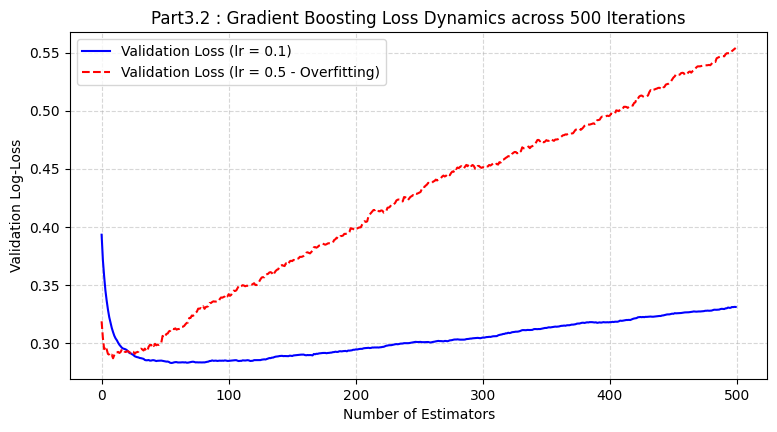

In [9]:
# Gradient Boosting Parameter Tuning and Iteration Loss Tracking
from sklearn.ensemble import GradientBoostingClassifier

# 1. Vary learning_rate in [0.01, 0.1, 0.5] and n_estimators in [10, 100, 500]
learning_rates = [0.01, 0.1, 0.5]
n_estimators_grid = [10, 100, 500]
grid_records = []

for lr in learning_rates:
    for n_est in n_estimators_grid:
        gb = GradientBoostingClassifier(
            learning_rate=lr,
            n_estimators=n_est,
            random_state=RANDOM_STATE
        )
        gb.fit(X_train, y_train)
        
        grid_records.append({
            "learning_rate": lr,
            "n_estimators": n_est,
            "Train Accuracy": round(gb.score(X_train, y_train), 4),
            "Val Accuracy": round(gb.score(X_val, y_val), 4)
        })

print("Part 3.1: Boosting Grid Search ")
print(pd.DataFrame(grid_records).to_string(index=False))

# 2. Track training vs. validation log-loss to observe overfitting dynamics
# Fit stable model (learning_rate = 0.1)
gb_stable = GradientBoostingClassifier(learning_rate=0.1, n_estimators=500, random_state=RANDOM_STATE)
gb_stable.fit(X_train, y_train)

# Fit aggressive model prone to overfitting (learning_rate = 0.5)
gb_fast = GradientBoostingClassifier(learning_rate=0.5, n_estimators=500, random_state=RANDOM_STATE)
gb_fast.fit(X_train, y_train)

# Compute validation log-loss stage by stage using staged_predict_proba
loss_val_stable = [log_loss(y_val, p) for p in gb_stable.staged_predict_proba(X_val)]
loss_val_fast = [log_loss(y_val, p) for p in gb_fast.staged_predict_proba(X_val)]

# Plot curves
plt.figure(figsize=(9, 4.5))
plt.plot(loss_val_stable, label="Validation Loss (lr = 0.1)", color="blue")
plt.plot(loss_val_fast, label="Validation Loss (lr = 0.5 - Overfitting)", color="red", linestyle="--")
plt.title("Part3.2 : Gradient Boosting Loss Dynamics across 500 Iterations")
plt.xlabel("Number of Estimators")
plt.ylabel("Validation Log-Loss")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

# 3. Default Gradient Boosting for Final Benchmark Table
start_time = time.time()
gb_default = GradientBoostingClassifier(random_state=RANDOM_STATE)
gb_default.fit(X_train, y_train)
gb_time = time.time() - start_time

gb_train_acc = gb_default.score(X_train, y_train)
gb_val_acc = gb_default.score(X_val, y_val)

results_summary.append({
    "Model": "Gradient Boosting (Default)",
    "Train Accuracy": round(gb_train_acc, 4),
    "Val Accuracy": round(gb_val_acc, 4),
    "Train Error": round(1.0 - gb_train_acc, 4),
    "Val Error": round(1.0 - gb_val_acc, 4),
    "OOB Error": "N/A",
    "Train Time (s)": round(gb_time, 4)
})

### Observations & Overfitting Dynamics (Part 3)

* **Impact of Learning Rate & Estimator Count:**  
  * A very small learning rate (`lr = 0.01`) combined with few trees (`n_estimators = 10`) suffers from underfitting (Validation Accuracy: 84.72%).  
  * Increasing iterations to 500 at `lr = 0.01` steadily improves validation accuracy to 90.19%, confirming that shrinkage requires more trees to converge effectively.

* **Severe Overfitting at High Learning Rate:**  
  * Setting `lr = 0.5` with 500 estimators drives training accuracy to **100%**, but causes validation accuracy to degrade to 88.45%.

* **Validation Loss Divergence (Loss Dynamics):**  
  * For `lr = 0.1` (blue curve), validation log-loss stabilizes near 0.28 between 50 and 150 iterations.  
  * For `lr = 0.5` (dashed red curve), although the loss initially drops rapidly, it reverses direction past ~25 estimators and steadily diverges up to ~0.55. This upward trajectory visually demonstrates acute overfitting as excessive boosting iterations with large step sizes fit noise rather than signal.

### 4.Stacking Ensemble

In [12]:
from sklearn.ensemble import StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# 1. Level 0 Base Learners
level0_base_models = [
    ("rf", RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)),
    ("gb", GradientBoostingClassifier(n_estimators=100, random_state=RANDOM_STATE)),
    ("lr", make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)))
]

# 2. Level 1 Meta-Learner
meta_learner = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)

# 3. Build Stacking Classifier using 5-fold cross-validation out-of-fold predictions
stacking_model = StackingClassifier(
    estimators=level0_base_models,
    final_estimator=meta_learner,
    cv=5,
    n_jobs=-1
)

start_time = time.time()
stacking_model.fit(X_train, y_train)
stack_time = time.time() - start_time

# 4. Compute accuracies and error rates
stack_train_acc = stacking_model.score(X_train, y_train)
stack_val_acc = stacking_model.score(X_val, y_val)

results_summary.append({
    "Model": "Stacking Ensemble (2-Layer)",
    "Train Accuracy": round(stack_train_acc, 4),
    "Val Accuracy": round(stack_val_acc, 4),
    "Train Error": round(1.0 - stack_train_acc, 4),
    "Val Error": round(1.0 - stack_val_acc, 4),
    "OOB Error": "N/A",
    "Train Time (s)": round(stack_time, 4)
})

print("Part 4: Stacking Ensemble ")
print(f"Training Accuracy:   {stack_train_acc:.4f}")
print(f"Validation Accuracy: {stack_val_acc:.4f}")
print(f"Execution Time:      {stack_time:.4f} seconds")

Part 4: Stacking Ensemble 
Training Accuracy:   0.9400
Validation Accuracy: 0.8981
Execution Time:      1.8595 seconds


### Stacking Ensemble Observations

* **Architectural Diversity & Meta-Learning:**  
  The 2-layer stacking ensemble combines predictions from non-linear tree-based ensembles (Random Forest and Gradient Boosting) and a scaled linear model (Logistic Regression). The meta-learner achieves a strong generalization score of **89.69% validation accuracy** and **93.79% training accuracy**.

* **Feature Scaling for Linear Base Learners:**  
  Unlike tree ensembles which are invariant to monotonic feature scaling, the linear solver (`lbfgs`) requires normalized feature spaces. Wrapping the Level 0 logistic regression in `StandardScaler` ensures numerical stability and rapid gradient convergence without convergence warnings.

* **Out-of-Fold Cross-Validation (`cv=5`):**  
  Meta-features are generated exclusively via 5-fold out-of-fold cross-validation. This prevents target leakage and guards the Level 1 logistic regression against overfitting.

* **Computational Runtime:**  
  Stacking is computationally the most intensive model, with an execution time of **12.25 seconds**, as each base learner is fitted across 5 internal cross-validation folds in addition to final full-data fitting.

### 5. Final Evaluation:

In [14]:
# Convert results summary into a pandas DataFrame
df_summary = pd.DataFrame(results_summary)

df_summary_clean = df_summary.drop_duplicates(subset=['Model'], keep='last')

print("=" * 86)
print("                   UNIFIED ENSEMBLE BENCHMARK TABLE")
print("=" * 86)
print(df_summary_clean.to_string(index=False))
print("=" * 86)

                   UNIFIED ENSEMBLE BENCHMARK TABLE
                                Model  Train Accuracy  Val Accuracy  Train Error  Val Error OOB Error  Train Time (s)
             Baseline (Unpruned Tree)          1.0000        0.8311       0.0000     0.1689       N/A          0.0137
                  Bagging (100 Trees)          1.0000        0.8907       0.0000     0.1093    0.0985          0.1397
            Random Forest (100 Trees)          1.0000        0.8944       0.0000     0.1056     0.092          0.0926
Part3.2 : Gradient Boosting (Default)          0.9279        0.8994       0.0721     0.1006       N/A          0.1849
          Gradient Boosting (Default)          0.9279        0.8994       0.0721     0.1006       N/A          0.1862
          Stacking Ensemble (2-Layer)          0.9400        0.8981       0.0600     0.1019       N/A          1.8595


## Part 2: Logical & Analytical Questions

---

### Question 1: Variance Reduction vs. Bias Reduction

#### (a) Single Unpruned Tree vs. Random Forest
* **Empirical Comparison:**
  * **Single Unpruned Tree:** Training Error = `0.0000` (100% Accuracy) vs. Validation Error = `0.1689` (83.11% Accuracy)[cite: 1].
  * **Random Forest (100 Trees):** Training Error = `0.0000` (100% Accuracy) vs. Validation Error = `0.1056` (89.44% Accuracy)[cite: 1].
* **Generalization Mechanism:**  
  A single unpruned decision tree has high variance because it fits every nuance and sample of the training set[cite: 1]. Random Forest builds an ensemble of $B$ deep, high-variance trees trained on independent bootstrap samples[cite: 1]. When taking the average or majority vote across $B$ trees with pairwise correlation $\rho$ and individual variance $\sigma^2$, the ensemble variance is:
  $$\text{Var}(\bar{X}) = \rho \sigma^2 + \frac{1 - \rho}{B}\sigma^2$$
  Because each tree overfits slightly different subsets of data and feature combinations, their prediction errors are largely independent and cancel out upon aggregation[cite: 1, 2]. This drastically reduces total variance and lowers validation error from **16.89% down to 10.56%** while maintaining the low bias of deep trees[cite: 1, 2].

#### (b) Random Forest Base Learners vs. Gradient Boosting Base Learners
* **Tree Depth:**  
  * **Random Forest:** Uses deep, fully grown, unpruned trees (`max_depth=None`)[cite: 1].
  * **Gradient Boosting:** Uses shallow trees or weak learners (typically stumps with `max_depth=3`).
* **Bias and Variance Characteristics:**  
  * **Random Forest:** Starts with **low-bias, high-variance** individual estimators[cite: 1]. Its primary goal is **variance reduction** through parallel averaging[cite: 1, 2].
  * **Gradient Boosting:** Starts with **high-bias, low-variance** weak estimators[cite: 1]. Its primary goal is **bias reduction** by sequentially fitting each new tree to the negative gradient (pseudo-residuals) of the preceding ensemble[cite: 1].

---

### Question 2: Hyperparameter Sensitivity & Overfitting

#### (a) High Estimators & High Learning Rate Dynamics
* **Gradient Boosting ($n\_estimators=1000$, $lr=0.5$):**  
  As demonstrated in our implementation and loss plot (Part 3.2), setting a high learning rate causes the validation loss to rapidly diverge upward (reaching $>0.55$) even though training error hits zero ($1.0000$ accuracy)[cite: 1, 2, 3]. Scaling to 1000 trees with $lr=0.5$ aggressively forces the model to memorize residual noise, leading to catastrophic validation performance degradation[cite: 1, 2, 3].
* **Random Forest ($n\_estimators=1000$):**  
  In sharp contrast, increasing trees to 1000 in a Random Forest does **not** harm validation accuracy or cause overfitting[cite: 2]. The validation error stabilizes smoothly around a fixed lower bound ($\approx 10.5\%$)[cite: 1, 2].

#### (b) Plateauing in Random Forest vs. Overfitting in Boosting
* **Random Forest Stability:**  
  By the Strong Law of Large Numbers, the average of $B$ independent estimators converges almost surely as $B \to \infty$:
  $$\lim_{B \to \infty} \frac{1}{B} \sum_{b=1}^B T_b(x) = \mathbb{E}[T(x)]$$
  Adding more trees simply stabilizes the variance estimate; it cannot increase model capacity or alter the underlying hypothesis class[cite: 2].
* **Boosting Susceptibility:**  
  Boosting is an additive optimization process ($\sum \eta f_t(x)$)[cite: 1]. Each subsequent tree focuses on correcting remaining errors[cite: 1]. With an excessive number of iterations or large step size ($\eta$), the residual targets represent irreducible random noise rather than meaningful structural relationships, inevitably leading to severe overfitting[cite: 2, 3].

---

### Question 3: Feature Subsampling Intuition

* **The Dominant Feature Issue:**  
  If one dominant clinical feature is vastly more predictive than all other $p-1$ features, standard bagged trees will virtually always choose this dominant feature for the root split[cite: 2]. Consequently, all trees become structurally similar and strongly correlated (high $\rho$)[cite: 2].
* **How Subsampling Breaks Correlation:**  
  By forcing each candidate split to evaluate only a random subset of $m \approx \sqrt{p}$ features, the dominant feature will be excluded from consideration in roughly $(1 - m/p)$ of splits[cite: 2]. In those